# 02_fomc_event_study.ipynb

Set repo root

In [2]:
from pathlib import Path
import os

p = Path.cwd().resolve()
while not (p / ".git").exists() and p != p.parent:
    p = p.parent

os.chdir(p)
print("CWD set to repo root:", Path.cwd())


CWD set to repo root: C:\Users\Andre\iCloud Drive_new\iCloudDrive\Desktop\Thesis\thesis-vrp-fomc


Confirm where the file is

In [4]:
from pathlib import Path
print(Path("data/processed/vrp_vix_daily.parquet").resolve())
print("Exists?", Path("data/processed/vrp_vix_daily.parquet").exists())


C:\Users\Andre\iCloud Drive_new\iCloudDrive\Desktop\Thesis\thesis-vrp-fomc\data\processed\vrp_vix_daily.parquet
Exists? True


Load VRP parquet

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

vrp = pd.read_parquet("data/processed/vrp_vix_daily.parquet")
vrp["date"] = pd.to_datetime(vrp["date"])
vrp = vrp.set_index("date").sort_index()

print("VRP sample:", vrp.index.min(), "to", vrp.index.max(), "rows:", len(vrp))
vrp[["sp500","vix","iv","rv_fwd","vrp"]].head()


VRP sample: 2016-02-08 00:00:00 to 2026-01-05 00:00:00 rows: 2492


,sp500,vix,iv,rv_fwd,vrp
date,,,,,
2016-02-08,1853.44,26.00,0.067600,0.027662,0.039938
2016-02-09,1852.21,26.54,0.070437,0.030686,0.039751
2016-02-10,1851.86,26.29,0.069116,0.030704,0.038413
2016-02-11,1829.08,28.14,0.079186,0.028988,0.050198
2016-02-12,1864.78,25.40,0.064516,0.025065,0.039451


Load USMPD statement events

In [7]:
usmpd_path = Path("data/raw/USMPD.xlsx")
assert usmpd_path.exists(), "Missing data/raw/USMPD.xlsx. Download it from the SF Fed USMPD page and save it there."

stm = pd.read_excel(usmpd_path, sheet_name="Statements")
stm["Date"] = pd.to_datetime(stm["Date"])
stm = stm.sort_values("Date")

# Keep scheduled statements (Unscheduled == 0)
stm = stm[stm["Unscheduled"] == 0].copy()

# Keep only dates that overlap with your VRP sample
stm = stm[(stm["Date"] >= vrp.index.min()) & (stm["Date"] <= vrp.index.max())].copy()

print("Scheduled statement events in VRP sample:", len(stm))
stm[["Date","SEP","Unscheduled","ED1","ED2","ED3","ED4"]].head()


Scheduled statement events in VRP sample: 78


,Date,SEP,Unscheduled,ED1,ED2,ED3,ED4
188,2016-03-16,1,0,-0.055,-0.080,-0.100,-0.110
189,2016-04-27,0,0,0.005,0.010,0.010,0.015
190,2016-06-15,1,0,-0.035,-0.045,-0.050,-0.055
191,2016-07-27,0,0,0.005,0.005,0.005,0.005
192,2016-09-21,1,0,-0.025,-0.025,-0.025,-0.030


Align statement dates to trading days

In [8]:
idx = vrp.index

def align_to_trading_day(d):
    # if exact trading day exists, use it; otherwise move to next trading day
    if d in idx:
        return d
    pos = idx.searchsorted(d)
    if pos >= len(idx):
        return pd.NaT
    return idx[pos]

stm["event_date"] = stm["Date"].apply(align_to_trading_day)
stm = stm.dropna(subset=["event_date"])

print("Events after alignment:", len(stm))
print("Example alignment check:")
print(stm[["Date","event_date"]].head())


Events after alignment: 78
Example alignment check:
          Date event_date
188 2016-03-16 2016-03-16
189 2016-04-27 2016-04-27
190 2016-06-15 2016-06-15
191 2016-07-27 2016-07-27
192 2016-09-21 2016-09-21


Event-study: average VRP t-5 to t+5 around FOMC meetings

In [9]:
W = 5
offs = np.arange(-W, W+1)

event_rows = []
used_dates = []

for d in pd.to_datetime(stm["event_date"]).unique():
    pos = idx.get_loc(d)
    if pos - W < 0 or pos + W >= len(idx):
        continue
    window = vrp["vrp"].iloc[pos-W:pos+W+1].values
    event_rows.append(window)
    used_dates.append(d)

event_mat = np.vstack(event_rows)
event_mean = event_mat.mean(axis=0)
event_se = event_mat.std(axis=0, ddof=1) / np.sqrt(event_mat.shape[0])

print("Events used in event plot:", event_mat.shape[0])


Events used in event plot: 78


Plot and save thesis figure #1

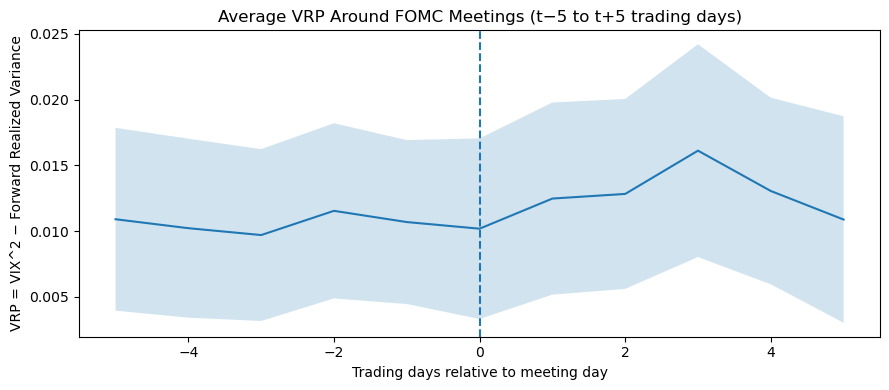

Saved: reports/figures/fomc_event_vrp_tminus5_tplus5.png


In [10]:
Path("reports/figures").mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9,4))
plt.plot(offs, event_mean)
plt.fill_between(offs, event_mean - 1.96*event_se, event_mean + 1.96*event_se, alpha=0.2)
plt.axvline(0, linestyle="--")
plt.title("Average VRP Around FOMC Meetings (t−5 to t+5 trading days)")
plt.xlabel("Trading days relative to meeting day")
plt.ylabel("VRP = VIX^2 − Forward Realized Variance")
plt.tight_layout()
plt.savefig("reports/figures/fomc_event_vrp_tminus5_tplus5.png", dpi=200)
plt.show()

print("Saved: reports/figures/fomc_event_vrp_tminus5_tplus5.png")


Surprise series = PC1 (ED1...ED4) on statement days

In [11]:
from sklearn.decomposition import PCA

X = stm[["ED1","ED2","ED3","ED4"]].astype(float)
mask = X.notna().all(axis=1)

X_std = (X[mask] - X[mask].mean()) / X[mask].std()
pca = PCA(n_components=1).fit(X_std)

s = pca.transform(X_std).ravel()

# Orient sign so positive aligns with an increase in the rate path (tightening)
if np.corrcoef(s, X_std.sum(axis=1))[0,1] < 0:
    s = -s

stm.loc[mask, "surprise_pc1"] = s

stm[["Date","event_date","ED1","ED2","ED3","ED4","surprise_pc1"]].head()


,Date,event_date,ED1,ED2,ED3,ED4,surprise_pc1
188,2016-03-16,2016-03-16,-0.055,-0.080,-0.100,-0.110,-3.888974
189,2016-04-27,2016-04-27,0.005,0.010,0.010,0.015,0.418774
190,2016-06-15,2016-06-15,-0.035,-0.045,-0.050,-0.055,-2.136843
191,2016-07-27,2016-07-27,0.005,0.005,0.005,0.005,0.216385
192,2016-09-21,2016-09-21,-0.025,-0.025,-0.025,-0.030,-1.252957


Save meeting-level dataset for the regressions

In [13]:
meet = stm.merge(
    vrp.reset_index(),
    left_on="event_date",
    right_on="date",
    how="left",
    validate="one_to_one"
)

keep_cols = [
    "Date","event_date","SEP","Unscheduled",
    "ED1","ED2","ED3","ED4","surprise_pc1",
    "sp500","vix","iv","rv_fwd","vrp"
]
meet = meet[keep_cols].sort_values("event_date")

Path("data/processed").mkdir(parents=True, exist_ok=True)
meet.to_parquet("data/processed/meetings_vrp_usmpd.parquet", index=False)

print("Saved: data/processed/meetings_vrp_usmpd.parquet")
print("Meetings dataset rows:", len(meet))
meet.head()
meet[["event_date","vrp","surprise_pc1"]].head()

Saved: data/processed/meetings_vrp_usmpd.parquet
Meetings dataset rows: 78


,event_date,vrp,surprise_pc1
0,2016-03-16,0.012557,-3.888974
1,2016-04-27,0.006326,0.418774
2,2016-06-15,0.005135,-2.136843
3,2016-07-27,0.013627,0.216385
4,2016-09-21,0.009939,-1.252957
